In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
!pip install -q openai-whisper
!pip install -q ffmpeg-python
!apt-get install -y ffmpeg

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 138.8 kB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 134 not upgraded.


In [3]:
import whisper

In [ ]:
base_model = whisper.load_model("medium")

100%|████████████████████████████████████████| 461M/461M [00:04<00:00, 106MiB/s]


In [15]:


df = pd.read_parquet("/kaggle/input/datasets/redamalki/dataset/data/train-00000-of-00005.parquet")

print(df.head())
print(df.columns)

                                               audio  \
0  {'bytes': b'RIFF\x9a\xa5\x02\x00WAVEfmt \x10\x...   
1  {'bytes': b'RIFF\xf2\xea\x02\x00WAVEfmt \x10\x...   
2  {'bytes': b'RIFF\xf2*\x03\x00WAVEfmt \x10\x00\...   
3  {'bytes': b'RIFFF\xa0\x02\x00WAVEfmt \x10\x00\...   
4  {'bytes': b'RIFFF\x00\x02\x00WAVEfmt \x10\x00\...   

                              darija_Latn                  darija_Arab_new  \
0    homa mkhbbyin chi haja, ana mti99en!    هوما مخبيين شي حاجة انا متيقن   
1      bayna homa tay7awlo ib9aw mbrrdin.  باينة هوما كيحاولو يبقاو مبردين   
2  loTilat mabaynach fihom mori7in bzzaf.  لوطيلات مبيناش فيهم مريحين بزاف   
3      ghaliban ghayjrriw 3lih mn lkhdma!      غالبا غيجريو عليه من الخدمة   
4                     Tab3an rah mkta2eb!                   طبعا راه مكتئب   

                                             english  \
0                They're hiding something, I'm sure!   
1    It's obvious they're trying to keep their cool.   
2            the hotels do

In [16]:
import pandas as pd
from pathlib import Path

# Folder containing all parquet shards
data_path = Path("/kaggle/input/datasets/redamalki/dataset/data")

# Get all parquet files
parquet_files = sorted(data_path.glob("*.parquet"))

print("Files found:")
for f in parquet_files:
    print(f)

Files found:
/kaggle/input/datasets/redamalki/dataset/data/train-00000-of-00005.parquet
/kaggle/input/datasets/redamalki/dataset/data/train-00001-of-00005.parquet
/kaggle/input/datasets/redamalki/dataset/data/train-00002-of-00005.parquet
/kaggle/input/datasets/redamalki/dataset/data/train-00003-of-00005.parquet
/kaggle/input/datasets/redamalki/dataset/data/train-00004-of-00005.parquet


In [17]:
df = pd.concat(
    [pd.read_parquet(file) for file in parquet_files],
    ignore_index=True
)

print(df.shape)
print(df.head())
print(df.columns)

(12743, 5)
                                               audio  \
0  {'bytes': b'RIFF\x9a\xa5\x02\x00WAVEfmt \x10\x...   
1  {'bytes': b'RIFF\xf2\xea\x02\x00WAVEfmt \x10\x...   
2  {'bytes': b'RIFF\xf2*\x03\x00WAVEfmt \x10\x00\...   
3  {'bytes': b'RIFFF\xa0\x02\x00WAVEfmt \x10\x00\...   
4  {'bytes': b'RIFFF\x00\x02\x00WAVEfmt \x10\x00\...   

                              darija_Latn                  darija_Arab_new  \
0    homa mkhbbyin chi haja, ana mti99en!    هوما مخبيين شي حاجة انا متيقن   
1      bayna homa tay7awlo ib9aw mbrrdin.  باينة هوما كيحاولو يبقاو مبردين   
2  loTilat mabaynach fihom mori7in bzzaf.  لوطيلات مبيناش فيهم مريحين بزاف   
3      ghaliban ghayjrriw 3lih mn lkhdma!      غالبا غيجريو عليه من الخدمة   
4                     Tab3an rah mkta2eb!                   طبعا راه مكتئب   

                                             english  \
0                They're hiding something, I'm sure!   
1    It's obvious they're trying to keep their cool.   
2            th

In [6]:
references = df["darija_Arab_new"]

In [7]:
references

0            هوما مخبيين شي حاجة انا متيقن
1          باينة هوما كيحاولو يبقاو مبردين
2          لوطيلات مبيناش فيهم مريحين بزاف
3              غالبا غيجريو عليه من الخدمة
4                           طبعا راه مكتئب
                       ...                
2544    ديك الطوموبيلا اللي لهيه راه ديالي
2545                    هاديك مدرسة مزيانة
2546                       هدا كتاب ديالها
2547                          هادشي مكافيش
2548                     الطوموبيل تصاوبات
Name: darija_Arab_new, Length: 2549, dtype: object

In [14]:
import os
import io
from pathlib import Path
import soundfile as sf

output_dir = Path("/kaggle/working/audio_files")
output_dir.mkdir(exist_ok=True)

for idx, row in df.iterrows():
    audio_bytes = row['audio']['bytes']  # get the bytes
    file_path = output_dir / f"audio_{idx}.wav"
    
    # Save bytes as .wav
    with open(file_path, "wb") as f:
        f.write(audio_bytes)

In [7]:
result = model.transcribe("/kaggle/working/audios/audio_0.wav", language="ar")

print(result["text"])

 هم مخبنشي حاجة أنا متقن


In [15]:
import os

folder_path = "/kaggle/working/audios"

results = []

for audio in os.listdir(folder_path):

    audio_path = os.path.join(folder_path, audio)

    result = model.transcribe(audio_path, language="ar")
    i += 1
    

    results.append(result)
    

In [16]:
len(results)

2549

In [17]:
import pickle

# Save
with open("/kaggle/working/transcriptions.pkl", "wb") as f:
    pickle.dump(results, f)

In [12]:
files = []
for file in os.listdir(folder_path):
    path = os.path.join(folder_path,file)
    files.append(path)


In [13]:
len(files)

2549

In [1]:
print("reda")

reda


In [10]:
import pickle

In [11]:
path = "/kaggle/input/datasets/redamalki/transcriptions/transcriptions.pkl"

with open(path, "rb") as f:
    files = pickle.load(f)

print(type(files))
print(len(files))

<class 'list'>
2549


In [12]:
files[1]

{'text': ' وشهدشي',
 'segments': [{'id': 0,
   'seek': 0,
   'start': 0.0,
   'end': 1.28,
   'text': ' وشهدشي',
   'tokens': [50364, 4032, 8592, 3224, 3215, 8592, 1829, 50428],
   'temperature': 0.0,
   'avg_logprob': -0.8254975212944878,
   'compression_ratio': 0.631578947368421,
   'no_speech_prob': 0.03554973378777504}],
 'language': 'ar'}

In [13]:
files[1]["text"]


' وشهدشي'

In [9]:
files[:300]

b'\x80\x04\x95%\x00\x01\x00\x00\x00\x00\x00]\x94(}\x94(\x8c\x04text\x94\x8cj \xd9\x84\xd9\x82\xd8\xaf \xd9\x82\xd9\x84\xd8\xaa \xd9\x84\xd8\xaf\xd9\x8a\xd9\x83 \xd8\xb4\xd9\x8a\xd8\xa1 \xd8\xa3\xd8\xb4\xd9\x8a\xd8\xa7\xd8\xa1 \xd9\x88\xd9\x84\xd9\x83\xd9\x86 \xd9\x84\xd9\x85 \xd9\x8a\xd8\xb1\xd8\xaf\xd8\xaa \xd9\x84\xd8\xaf\xd9\x8a\xd9\x83 \xd8\xa7\xd9\x84\xd9\x88\xd9\x82\xd8\xaa \xd9\x88\xd9\x82\xd9\x84\xd8\xaa \xd9\x88\xd9\x8a\xd8\xaa\xd8\xad\xd8\xb1\xd9\x83\x94\x8c\x08segments\x94]\x94}\x94(\x8c\x02id\x94K\x00\x8c\x04seek\x94K\x00\x8c\x05start\x94G\x00\x00\x00\x00\x00\x00\x00\x00\x8c\x03end\x94G@\x10\x00\x00\x00\x00\x00\x00h\x02\x8cj \xd9\x84\xd9\x82\xd8\xaf \xd9\x82\xd9\x84\xd8\xaa \xd9\x84\xd8\xaf\xd9\x8a\xd9\x83 \xd8\xb4\xd9\x8a\xd8\xa1 \xd8\xa3\xd8\xb4\xd9\x8a\xd8\xa7\xd8\xa1 \xd9\x88\xd9\x84\xd9\x83\xd9\x86 \xd9\x84\xd9\x85 \xd9\x8a\xd8\xb1\xd8\xaf\xd8\xaa \xd9\x84\xd8\xaf\xd9\x8a\xd9\x83 \xd8\xa7\xd9\x84\xd9\x88\xd9\x82\xd8\xaa \xd9\x88\xd9\x82\xd9\x84\xd8\xaa \xd9\x88\xd9\x8a

In [14]:
predictions = [f["text"] for f in files]

In [15]:
import os

os.makedirs("/kaggle/working/audios", exist_ok=True)

audio_files = []

for i, row in df.iterrows():

    audio_bytes = row["audio"]["bytes"]

    filename = f"/kaggle/working/audios/audio_{i}.wav"

    with open(filename, "wb") as f:
        f.write(audio_bytes)

    audio_files.append(filename)

In [19]:
eval_df = pd.DataFrame({
    "audio": audio_files[:len(predictions)],
    "reference": references[:len(predictions)],
    "prediction": predictions
})

eval_df.head()

,audio,reference,prediction
0,/kaggle/working/audios/audio_0.wav,هوما مخبيين شي حاجة انا متيقن,لقد قلت لديك شيء أشياء ولكن لم يردت لديك الوق...
1,/kaggle/working/audios/audio_1.wav,باينة هوما كيحاولو يبقاو مبردين,وشهدشي
2,/kaggle/working/audios/audio_2.wav,لوطيلات مبيناش فيهم مريحين بزاف,حتاليس تلك الأوم
3,/kaggle/working/audios/audio_3.wav,غالبا غيجريو عليه من الخدمة,مزيان
4,/kaggle/working/audios/audio_4.wav,طبعا راه مكتئب,باش خسنين كون كن فاك كن خبل خلوسي لماكينش راي...


In [23]:
!pip install -q openai-whisper jiwer librosa soundfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 32.0 MB/s eta 0:00:0000:0100:01


In [13]:
import pandas as pd

df = pd.read_parquet("/kaggle/input/datasets/redamalki/dataset/data/train-00000-of-00005.parquet")

print(len(df))
df.head()

2549


,audio,darija_Latn,darija_Arab_new,english,darija_Arab_old
0,{'bytes': b'RIFF\x9a\xa5\x02\x00WAVEfmt \x10\x...,"homa mkhbbyin chi haja, ana mti99en!",هوما مخبيين شي حاجة انا متيقن,"They're hiding something, I'm sure!","هوما مخبّيين شي حاجة, أنا متيقّن!"
1,{'bytes': b'RIFF\xf2\xea\x02\x00WAVEfmt \x10\x...,bayna homa tay7awlo ib9aw mbrrdin.,باينة هوما كيحاولو يبقاو مبردين,It's obvious they're trying to keep their cool.,باينا هوما تايحاولو إبقاو مبرّدين.
2,{'bytes': b'RIFF\xf2*\x03\x00WAVEfmt \x10\x00\...,loTilat mabaynach fihom mori7in bzzaf.,لوطيلات مبيناش فيهم مريحين بزاف,the hotels don't seem very comfortable.,لوطيلات مابايناش فيهوم موريحين بزّاف.
3,{'bytes': b'RIFFF\xa0\x02\x00WAVEfmt \x10\x00\...,ghaliban ghayjrriw 3lih mn lkhdma!,غالبا غيجريو عليه من الخدمة,he is probably about to be laid off by head of...,غاليبان غايجرّيو عليه من لخدما!
4,{'bytes': b'RIFFF\x00\x02\x00WAVEfmt \x10\x00\...,Tab3an rah mkta2eb!,طبعا راه مكتئب,of course he's depressive!,طابعان راه مكتاءب!


In [22]:
import whisper

model = whisper.load_model("small")

In [23]:
model = whisper.load_model("small", device="cuda")

In [24]:
import io
import librosa

results = []

for i, row in df.iterrows():

    audio_bytes = row["audio"]["bytes"]

    audio, sr = librosa.load(io.BytesIO(audio_bytes), sr=16000)

    prediction = model.transcribe(audio, language="ar")["text"]

    results.append({
        "id": i,
        "reference": row["darija_Arab_new"],
        "prediction": prediction
    })

In [25]:
eval_df = pd.DataFrame(results)

eval_df.head()

,id,reference,prediction
0,0,هوما مخبيين شي حاجة انا متيقن,هم مخبنشي حاجة أنا متقن
1,1,باينة هوما كيحاولو يبقاو مبردين,بينهما كحولوا بقام بردين
2,2,لوطيلات مبيناش فيهم مريحين بزاف,لو طيلات ما بيناش فيهم مورحين بالزيف
3,3,غالبا غيجريو عليه من الخدمة,غالباً غيروا عليهم الخدمة
4,4,طبعا راه مكتئب,طبعا لنرهم كتائب


In [26]:
from jiwer import wer

eval_df["wer"] = eval_df.apply(
    lambda x: wer(x["reference"], x["prediction"]),
    axis=1
)

overall_wer = eval_df["wer"].mean()

print("Average WER:", overall_wer)

Average WER: 0.9362115706656483


In [28]:
eval_df[20:30]

,id,reference,prediction,wer
20,20,كنهضر على مراكش,كان هدر على مراركش,1.000000
21,21,بجوجنا كنخافو من الطيران,بجوجنا كان خفو من الطياران,0.750000
22,22,اولا,أولو؟,1.000000
23,23,من امتى بالسلامة كنعس كيعاون شي واحد,أمني متبسلمة كالناس جاعة وانتي واحد,0.857143
24,24,كنت عارفها,كنت عرفها,0.500000
25,25,اربي,أربى,1.000000
26,26,هادشي كلو الغلط ديالك,هادش كله لغالة ديلك,1.000000
27,27,فحالة وقعات كسيدة اش خاصنا نديرو,في حالة وقعتك سيدة أشخص ننديرو,1.000000
28,28,لاش جبتي معاك الشجرة للطيارة,لشي جبتي مكشزرط طيارة,0.800000
29,29,واش نتي حمقا ؟,أشنجي همقا؟,1.000000


In [29]:
eval_df.to_csv("/kaggle/working/whisper_eval.csv", index=False, encoding="utf-8")

In [5]:
import torch
from transformers import WhisperForConditionalGeneration, WhisperProcessor
from peft import PeftModel

# Processor
processor = WhisperProcessor.from_pretrained("openai/whisper-small")

# Base Whisper
base_model = WhisperForConditionalGeneration.from_pretrained(
    "openai/whisper-small",
    device_map="auto"
)

# Fine-tuned Whisper
lora_checkpoint = "/kaggle/input/datasets/redamalki/fine-tunned-whisper/fine_tunned_whisper"

fine_model = WhisperForConditionalGeneration.from_pretrained(
    "openai/whisper-small",
    device_map="auto"
)

fine_model = PeftModel.from_pretrained(fine_model, lora_checkpoint)

base_model.eval()
fine_model.eval()

preprocessor_config.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json: 0.00B [00:00, ?B/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

PeftModelForSeq2SeqLM(
  (base_model): LoraModel(
    (model): WhisperForConditionalGeneration(
      (model): WhisperModel(
        (encoder): WhisperEncoder(
          (conv1): Conv1d(80, 768, kernel_size=(3,), stride=(1,), padding=(1,))
          (conv2): Conv1d(768, 768, kernel_size=(3,), stride=(2,), padding=(1,))
          (embed_positions): Embedding(1500, 768)
          (layers): ModuleList(
            (0-11): 12 x WhisperEncoderLayer(
              (self_attn): WhisperAttention(
                (k_proj): Linear(in_features=768, out_features=768, bias=False)
                (v_proj): lora.Linear(
                  (base_layer): Linear(in_features=768, out_features=768, bias=True)
                  (lora_dropout): ModuleDict(
                    (default): Dropout(p=0.05, inplace=False)
                  )
                  (lora_A): ModuleDict(
                    (default): Linear(in_features=768, out_features=32, bias=False)
                  )
                  (lora_B): Mo

In [7]:
import io
import librosa

def transcribe(model, audio_bytes):

    audio_file = io.BytesIO(audio_bytes)

    audio, sr = librosa.load(audio_file, sr=16000)

    inputs = processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    input_features = inputs.input_features.to(model.device)

    predicted_ids = model.generate(
        input_features=input_features,
        task="transcribe",
        language="ar"
    )

    text = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    return text

In [8]:
df_results = []

for idx, row in df.iterrows():

    audio_bytes = row["audio"]["bytes"]

    original = row["darija_Arab_new"]

    base_pred = transcribe(base_model, audio_bytes)

    fine_pred = transcribe(fine_model, audio_bytes)

    df_results.append({
        "original_text": original,
        "base_whisper": base_pred,
        "fine_tuned_whisper": fine_pred
    })

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensA

In [28]:
eval_df_2 = pd.DataFrame()

In [29]:
from jiwer import wer

eval_df_2["wer"] = results_df.apply(
    lambda x: wer(x["original_text"], x["fine_tuned_whisper"]),
    axis=1
)

overall_wer = eval_df_2["wer"].mean()

print("Average WER:", overall_wer)

Average WER: 0.3555813873053014


In [ ]:
audio = row["audio"]["array"]
sr = row["audio"]["sampling_rate"]

In [21]:
results_df = pd.DataFrame(df_results)

results_df.head()

,original_text,base_whisper,fine_tuned_whisper
0,هوما مخبيين شي حاجة انا متيقن,هم مخبنشي حاجة أنا متقن,هوما مخبين شي حاجة انا متيقن
1,باينة هوما كيحاولو يبقاو مبردين,بينهما كحولوا بقام بردين,باينة هما كيحاولو يبقاهم بريدين
2,لوطيلات مبيناش فيهم مريحين بزاف,لو طيلات ما بيناش فيهم مورحين بالزيف,الوطيلات مبيناش فيهم موريحين بزاف
3,غالبا غيجريو عليه من الخدمة,غالباً غيروا عليهم الخدمة,غالبان غا يجرو عليه من الخدمة
4,طبعا راه مكتئب,طبعا لنرحمك تائب,طبعا راه ما كتائب


In [22]:
results_df.to_csv("/kaggle/working/whisper_results.csv", index=False, encoding="utf-8-sig")
print("Saved! ✓")

Saved! ✓


In [12]:
!pip install jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 52.6 MB/s eta 0:00:00a 0:00:01


In [23]:
import pandas as pd
import numpy as np
from jiwer import wer, cer
import re

results_df = pd.DataFrame(df_results)

def normalize(text):
    text = str(text).lower().strip()
    return re.sub(r'\s+', ' ', text)

def safe_wer(ref, hyp):
    try: return wer(normalize(ref), normalize(hyp))
    except: return np.nan

def safe_cer(ref, hyp):
    try: return cer(normalize(ref), normalize(hyp))
    except: return np.nan

results_df["base_wer"]        = results_df.apply(lambda r: safe_wer(r["original_text"], r["base_whisper"]), axis=1)
results_df["fine_wer"]        = results_df.apply(lambda r: safe_wer(r["original_text"], r["fine_tuned_whisper"]), axis=1)
results_df["base_cer"]        = results_df.apply(lambda r: safe_cer(r["original_text"], r["base_whisper"]), axis=1)
results_df["fine_cer"]        = results_df.apply(lambda r: safe_cer(r["original_text"], r["fine_tuned_whisper"]), axis=1)
results_df["wer_improvement"] = results_df["base_wer"] - results_df["fine_wer"]

results_df.head()

,original_text,base_whisper,fine_tuned_whisper,base_wer,fine_wer,base_cer,fine_cer,wer_improvement
0,هوما مخبيين شي حاجة انا متيقن,هم مخبنشي حاجة أنا متقن,هوما مخبين شي حاجة انا متيقن,0.833333,0.166667,0.241379,0.034483,0.666667
1,باينة هوما كيحاولو يبقاو مبردين,بينهما كحولوا بقام بردين,باينة هما كيحاولو يبقاهم بريدين,1.000000,0.600000,0.322581,0.161290,0.400000
2,لوطيلات مبيناش فيهم مريحين بزاف,لو طيلات ما بيناش فيهم مورحين بالزيف,الوطيلات مبيناش فيهم موريحين بزاف,1.200000,0.400000,0.258065,0.064516,0.800000
3,غالبا غيجريو عليه من الخدمة,غالباً غيروا عليهم الخدمة,غالبان غا يجرو عليه من الخدمة,0.800000,0.600000,0.222222,0.148148,0.200000
4,طبعا راه مكتئب,طبعا لنرحمك تائب,طبعا راه ما كتائب,0.666667,0.666667,0.428571,0.214286,0.000000


In [24]:
results_df.to_csv("/kaggle/working/whisper_results.csv", index=False, encoding="utf-8-sig")
print("Saved! ✓")

Saved! ✓


In [14]:
metrics_df = pd.DataFrame({
    "Metric":           ["Mean WER",  "Median WER", "Mean CER",  "Median CER"],
    "Base Whisper":     [results_df["base_wer"].mean(),   results_df["base_wer"].median(),
                         results_df["base_cer"].mean(),   results_df["base_cer"].median()],
    "Fine-tuned Whisper": [results_df["fine_wer"].mean(), results_df["fine_wer"].median(),
                           results_df["fine_cer"].mean(), results_df["fine_cer"].median()],
})
metrics_df["Improvement"] = metrics_df["Base Whisper"] - metrics_df["Fine-tuned Whisper"]
metrics_df["Improvement %"] = (metrics_df["Improvement"] / metrics_df["Base Whisper"] * 100).round(2).astype(str) + "%"
metrics_df = metrics_df.round(4)

pct_improved = (results_df["wer_improvement"] > 0).mean() * 100
print(f"Samples where fine-tuned WER < base WER: {pct_improved:.1f}%\n")
metrics_df

Samples where fine-tuned WER < base WER: 86.7%



,Metric,Base Whisper,Fine-tuned Whisper,Improvement,Improvement %
0,Mean WER,1.1574,0.3556,0.8018,69.28%
1,Median WER,1.0000,0.3333,0.6667,66.67%
2,Mean CER,0.7844,0.1133,0.6711,85.55%
3,Median CER,0.3750,0.0845,0.2905,77.46%


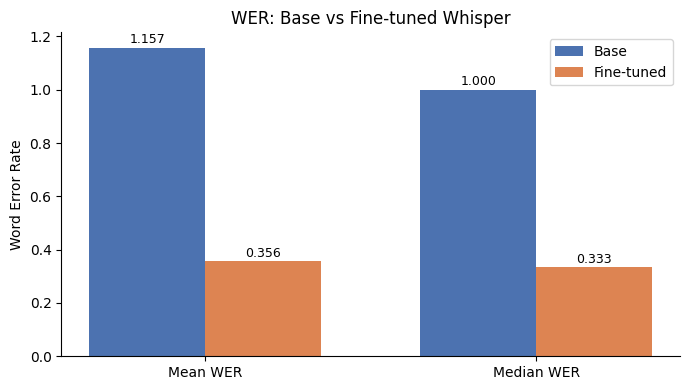

In [15]:
import matplotlib.pyplot as plt
import numpy as np

COLORS = {"base": "#4C72B0", "fine": "#DD8452"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(7, 4))
x, width = np.arange(2), 0.35
bars1 = ax.bar(x - width/2, metrics_df[metrics_df["Metric"].str.contains("WER")]["Base Whisper"],
               width, label="Base", color=COLORS["base"])
bars2 = ax.bar(x + width/2, metrics_df[metrics_df["Metric"].str.contains("WER")]["Fine-tuned Whisper"],
               width, label="Fine-tuned", color=COLORS["fine"])
ax.set_xticks(x); ax.set_xticklabels(["Mean WER", "Median WER"])
ax.set_ylabel("Word Error Rate"); ax.set_title("WER: Base vs Fine-tuned Whisper")
ax.legend()
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

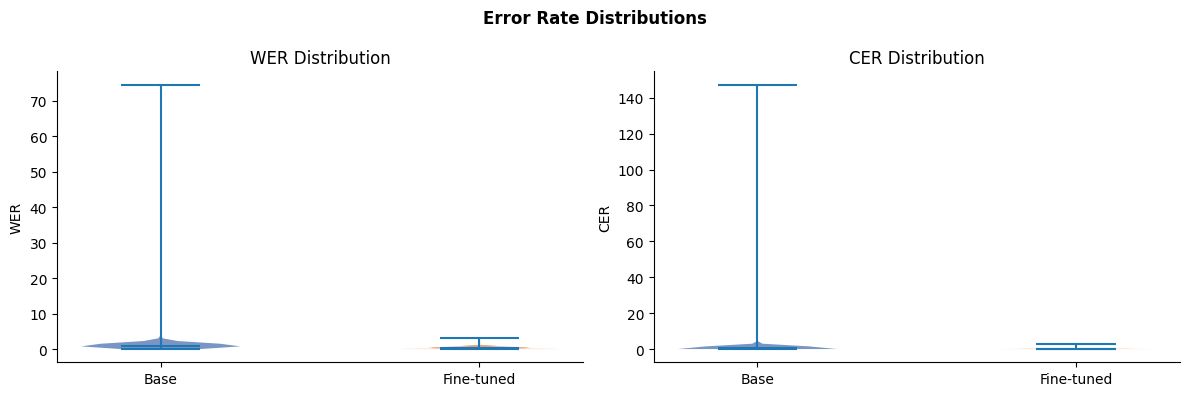

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Violin - WER
parts = axes[0].violinplot(
    [results_df["base_wer"].dropna(), results_df["fine_wer"].dropna()],
    positions=[1, 2], showmedians=True
)
for i, pc in enumerate(parts["bodies"]):
    pc.set_facecolor([COLORS["base"], COLORS["fine"]][i]); pc.set_alpha(0.75)
axes[0].set_xticks([1, 2]); axes[0].set_xticklabels(["Base", "Fine-tuned"])
axes[0].set_ylabel("WER"); axes[0].set_title("WER Distribution")

# Violin - CER
parts2 = axes[1].violinplot(
    [results_df["base_cer"].dropna(), results_df["fine_cer"].dropna()],
    positions=[1, 2], showmedians=True
)
for i, pc in enumerate(parts2["bodies"]):
    pc.set_facecolor([COLORS["base"], COLORS["fine"]][i]); pc.set_alpha(0.75)
axes[1].set_xticks([1, 2]); axes[1].set_xticklabels(["Base", "Fine-tuned"])
axes[1].set_ylabel("CER"); axes[1].set_title("CER Distribution")

plt.suptitle("Error Rate Distributions", fontweight="bold")
plt.tight_layout(); plt.show()

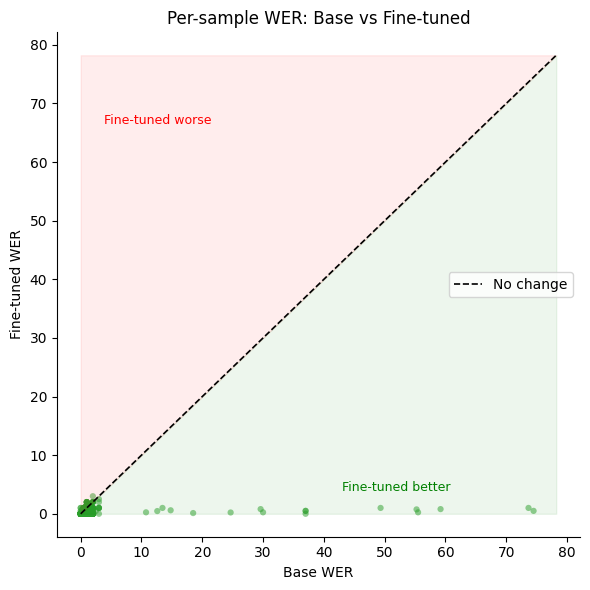

In [17]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(results_df["base_wer"], results_df["fine_wer"],
           alpha=0.5, s=20, color="#2ca02c", edgecolors="none")
lim = max(results_df[["base_wer","fine_wer"]].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1.2, label="No change")
ax.fill_between([0, lim], [0, lim], [0, 0], alpha=0.07, color="green")   # fine-tuned better
ax.fill_between([0, lim], [lim, lim], [0, lim], alpha=0.07, color="red") # fine-tuned worse
ax.text(lim*0.05, lim*0.85, "Fine-tuned worse", color="red",   fontsize=9)
ax.text(lim*0.55, lim*0.05, "Fine-tuned better", color="green", fontsize=9)
ax.set_xlabel("Base WER"); ax.set_ylabel("Fine-tuned WER")
ax.set_title("Per-sample WER: Base vs Fine-tuned"); ax.legend()
plt.tight_layout(); plt.show()

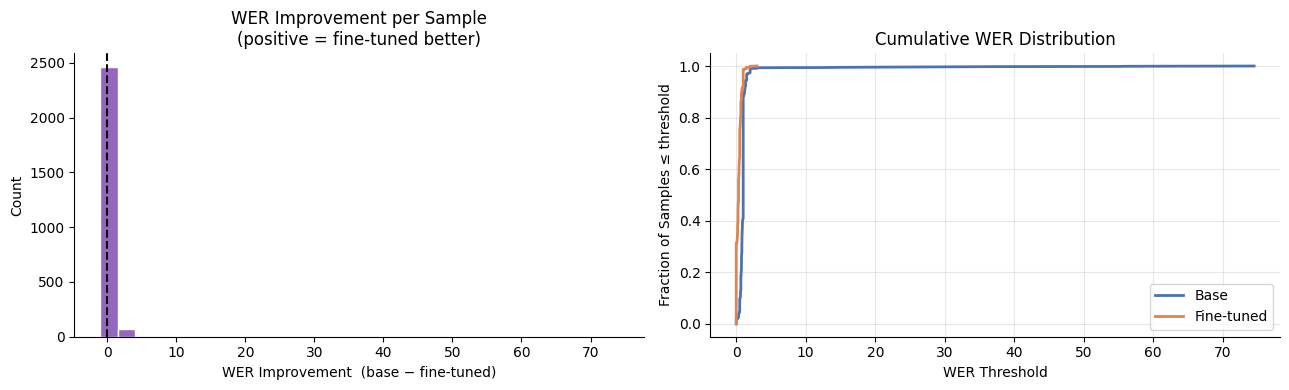

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram of improvement
axes[0].hist(results_df["wer_improvement"], bins=30, color="#9467bd", edgecolor="white")
axes[0].axvline(0, color="black", lw=1.5, linestyle="--")
axes[0].set_xlabel("WER Improvement  (base − fine-tuned)")
axes[0].set_ylabel("Count")
axes[0].set_title("WER Improvement per Sample\n(positive = fine-tuned better)")

# Cumulative WER
for label, col, c in [("Base", "base_wer", COLORS["base"]), ("Fine-tuned", "fine_wer", COLORS["fine"])]:
    s = np.sort(results_df[col].dropna())
    axes[1].plot(s, np.arange(1, len(s)+1)/len(s), label=label, color=c, lw=2)
axes[1].set_xlabel("WER Threshold"); axes[1].set_ylabel("Fraction of Samples ≤ threshold")
axes[1].set_title("Cumulative WER Distribution")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

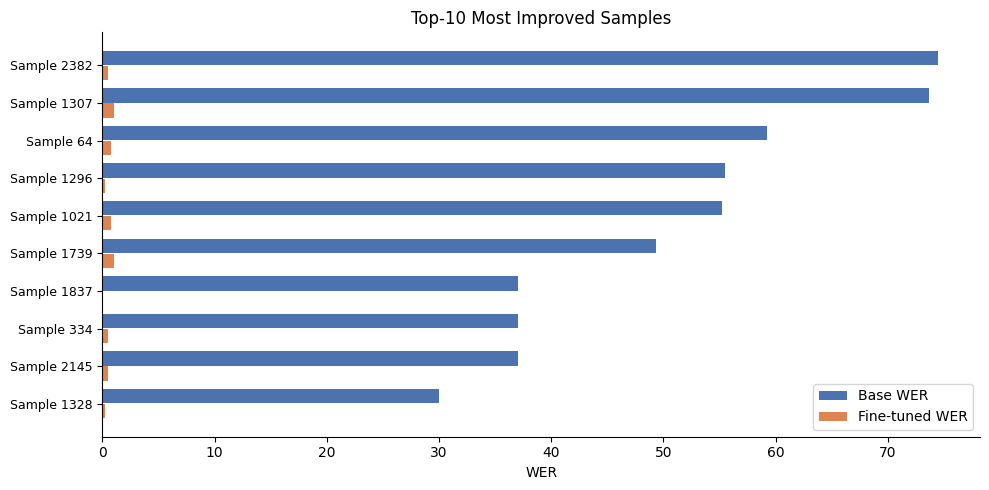

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
top10 = results_df.nlargest(10, "wer_improvement").reset_index()
y = np.arange(len(top10))
ax.barh(y - 0.2, top10["base_wer"], 0.38, color=COLORS["base"], label="Base WER")
ax.barh(y + 0.2, top10["fine_wer"], 0.38, color=COLORS["fine"], label="Fine-tuned WER")
ax.set_yticks(y)
ax.set_yticklabels([f"Sample {i}" for i in top10["index"]], fontsize=9)
ax.set_xlabel("WER"); ax.set_title("Top-10 Most Improved Samples")
ax.legend(); ax.invert_yaxis()
plt.tight_layout(); plt.show()

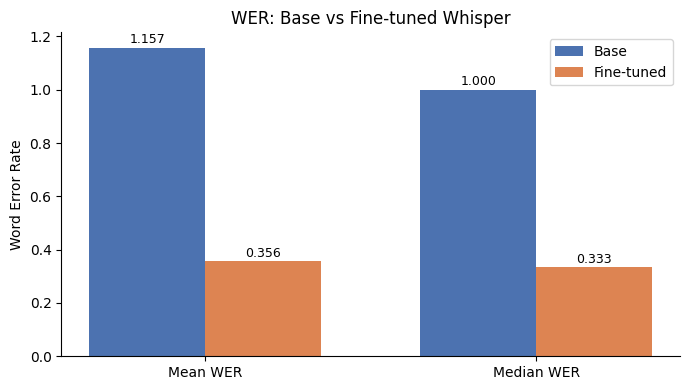

✓ plot1_wer_bar.png


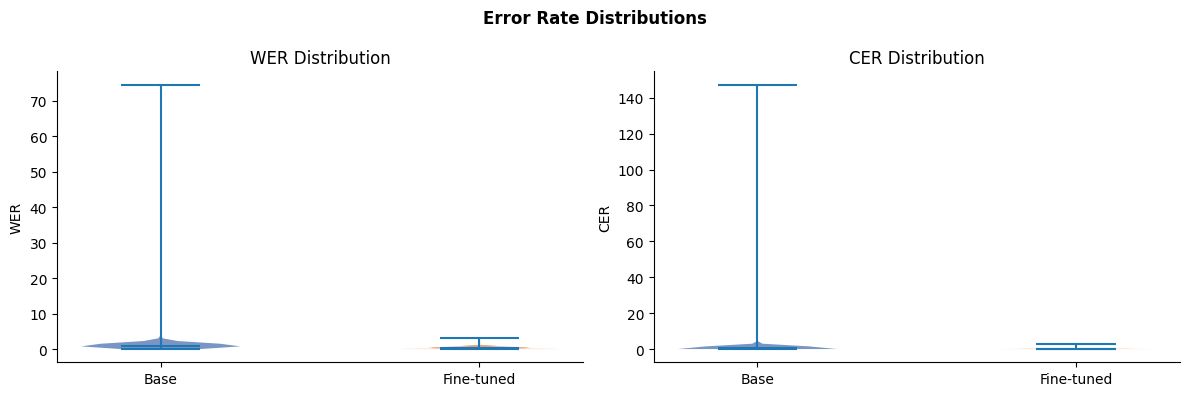

✓ plot2_violin.png


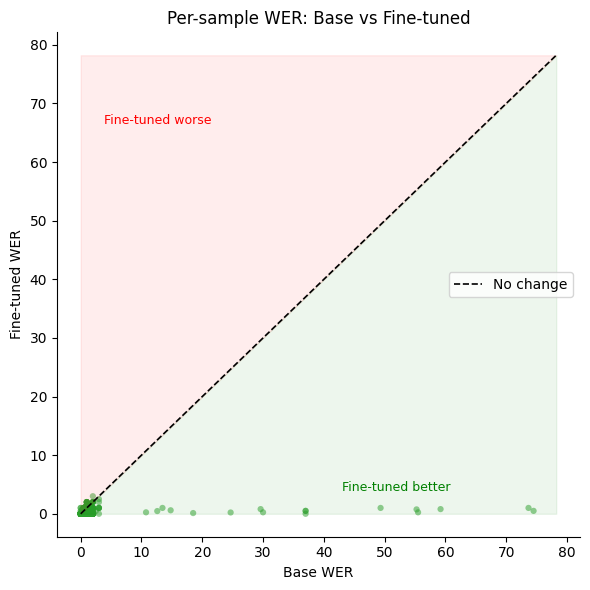

✓ plot3_scatter.png


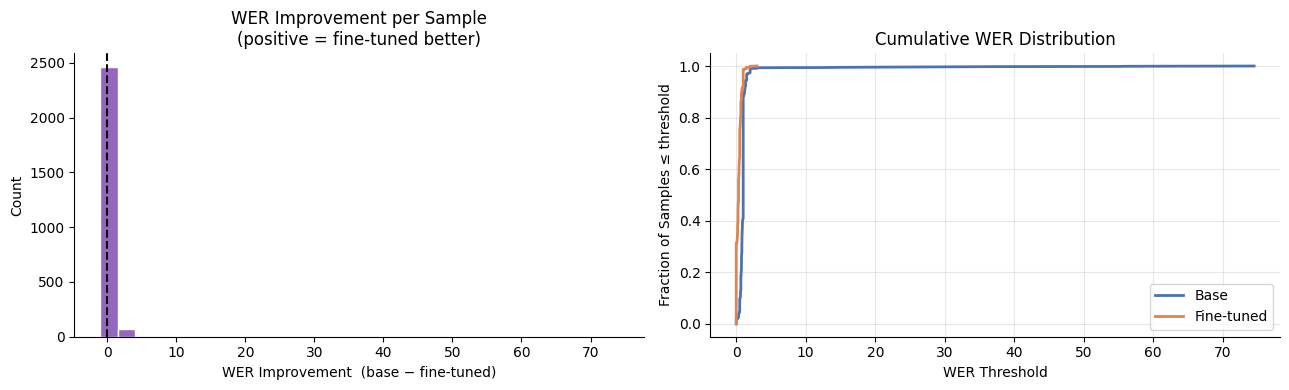

✓ plot4_histogram_cdf.png


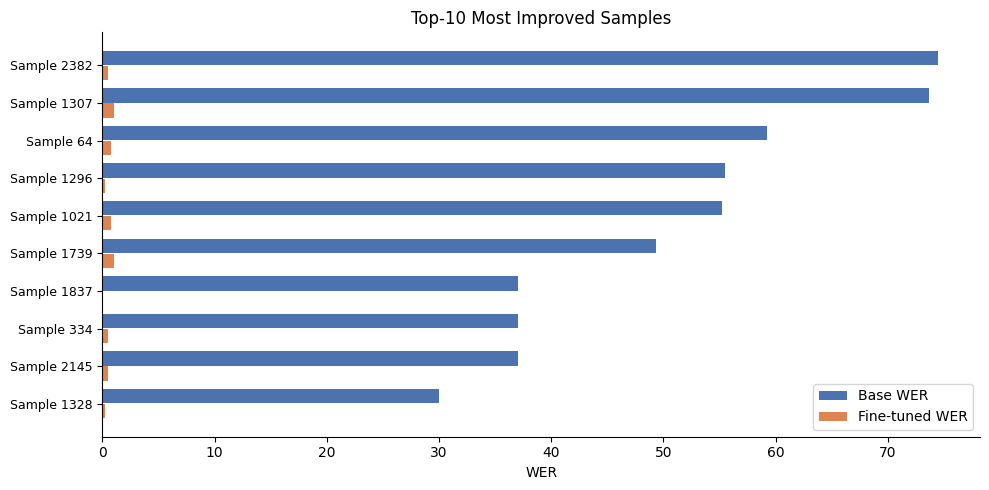

✓ plot5_top10.png

✅ All plots saved! Download 'all_plots.zip' from the Output tab.


In [20]:
import os
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

save_dir = "/kaggle/working/plots"
os.makedirs(save_dir, exist_ok=True)

# ── Plot 1: WER Bar Chart ────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
x, width = np.arange(2), 0.35
wer_rows = metrics_df[metrics_df["Metric"].str.contains("WER")]
bars1 = ax.bar(x - width/2, wer_rows["Base Whisper"],       width, label="Base",       color=COLORS["base"])
bars2 = ax.bar(x + width/2, wer_rows["Fine-tuned Whisper"], width, label="Fine-tuned", color=COLORS["fine"])
ax.set_xticks(x); ax.set_xticklabels(["Mean WER", "Median WER"])
ax.set_ylabel("Word Error Rate"); ax.set_title("WER: Base vs Fine-tuned Whisper")
ax.legend()
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(f"{save_dir}/plot1_wer_bar.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot1_wer_bar.png")

# ── Plot 2: Violin WER & CER ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col_base, col_fine, ylabel, title in [
    (axes[0], "base_wer", "fine_wer", "WER", "WER Distribution"),
    (axes[1], "base_cer", "fine_cer", "CER", "CER Distribution"),
]:
    parts = ax.violinplot([results_df[col_base].dropna(), results_df[col_fine].dropna()],
                          positions=[1, 2], showmedians=True)
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor([COLORS["base"], COLORS["fine"]][i]); pc.set_alpha(0.75)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Base", "Fine-tuned"])
    ax.set_ylabel(ylabel); ax.set_title(title)
plt.suptitle("Error Rate Distributions", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{save_dir}/plot2_violin.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot2_violin.png")

# ── Plot 3: Per-sample Scatter ───────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(results_df["base_wer"], results_df["fine_wer"],
           alpha=0.5, s=20, color="#2ca02c", edgecolors="none")
lim = max(results_df[["base_wer","fine_wer"]].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1.2, label="No change")
ax.fill_between([0, lim], [0, lim], [0, 0],    alpha=0.07, color="green")
ax.fill_between([0, lim], [lim, lim], [0, lim], alpha=0.07, color="red")
ax.text(lim*0.05, lim*0.85, "Fine-tuned worse",  color="red",   fontsize=9)
ax.text(lim*0.55, lim*0.05, "Fine-tuned better", color="green", fontsize=9)
ax.set_xlabel("Base WER"); ax.set_ylabel("Fine-tuned WER")
ax.set_title("Per-sample WER: Base vs Fine-tuned"); ax.legend()
plt.tight_layout()
plt.savefig(f"{save_dir}/plot3_scatter.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot3_scatter.png")

# ── Plot 4: Improvement Histogram + CDF ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(results_df["wer_improvement"], bins=30, color="#9467bd", edgecolor="white")
axes[0].axvline(0, color="black", lw=1.5, linestyle="--")
axes[0].set_xlabel("WER Improvement  (base − fine-tuned)")
axes[0].set_ylabel("Count")
axes[0].set_title("WER Improvement per Sample\n(positive = fine-tuned better)")
for label, col, c in [("Base", "base_wer", COLORS["base"]), ("Fine-tuned", "fine_wer", COLORS["fine"])]:
    s = np.sort(results_df[col].dropna())
    axes[1].plot(s, np.arange(1, len(s)+1)/len(s), label=label, color=c, lw=2)
axes[1].set_xlabel("WER Threshold"); axes[1].set_ylabel("Fraction of Samples ≤ threshold")
axes[1].set_title("Cumulative WER Distribution")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{save_dir}/plot4_histogram_cdf.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot4_histogram_cdf.png")

# ── Plot 5: Top-10 Most Improved ─────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
top10 = results_df.nlargest(10, "wer_improvement").reset_index()
y = np.arange(len(top10))
ax.barh(y - 0.2, top10["base_wer"], 0.38, color=COLORS["base"], label="Base WER")
ax.barh(y + 0.2, top10["fine_wer"], 0.38, color=COLORS["fine"], label="Fine-tuned WER")
ax.set_yticks(y)
ax.set_yticklabels([f"Sample {i}" for i in top10["index"]], fontsize=9)
ax.set_xlabel("WER"); ax.set_title("Top-10 Most Improved Samples")
ax.legend(); ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{save_dir}/plot5_top10.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot5_top10.png")

# ── Zip everything ───────────────────────────────────────────
import shutil
shutil.make_archive("/kaggle/working/all_plots", "zip", save_dir)
print("\n✅ All plots saved! Download 'all_plots.zip' from the Output tab.")

In [31]:
!pip install jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 38.7 MB/s eta 0:00:0000:0100:01


In [32]:
from jiwer import wer

results_df["wer_base"] = results_df.apply(
    lambda x: wer(x["original_text"], x["base_whisper"]),
    axis=1
)

results_df["wer_fine"] = results_df.apply(
    lambda x: wer(x["original_text"], x["fine_tuned_whisper"]),
    axis=1
)

In [33]:
results_df.to_csv(
    "/kaggle/working/whisper_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

In [34]:
results_df["improvement"] = results_df["wer_base"] - results_df["wer_fine"]

results_df.sort_values("improvement", ascending=False).head(10)

,original_text,base_whisper,fine_tuned_whisper,wer_base,wer_fine,improvement
2382,طوموبيلات ميريكانيين,اتصال الى اتصال الى اتصال الى اتصال الى اتصال...,الطوموبيلات ميريكانيين,74.500000,0.50,74.000000
1307,را هو فالكوزينة,لننظر الى الى الى الى الى الى الى الى الى الى...,راه وفي الكزينة,73.666667,1.00,72.666667
64,وياه غندير هادشي تا هو,نعم ، نعم ، نعم ، نعم ، نعم ، نعم ، نعم ، نعم...,وياه غنديرات شي تاهم,59.200000,0.80,58.400000
1296,كاين بنادم بزاف هنا,هل ترى أن ترى أن ترى أن ترى أن ترى أن ترى أن ...,كاين بناذم بزاف هنا,55.500000,0.25,55.250000
1021,تأخير اشنو هادشي تاني,كهر اسموا الى الى الى الى الى الى الى الى الى...,كأخير اشنو هادشي تا هنا,55.250000,0.75,54.500000
1739,عنيزة بعيد شوية,ونحن نحن نحن نحن نحن نحن نحن نحن نحن نحن نحن ...,الاني زاب عاد شوية,49.333333,1.00,48.333333
1837,ايه الى بغيتي,ايه.. ايه.. ايه.. ايه.. ايه.. ايه.. ايه.. ايه...,ايه الى بغيتي,37.000000,0.00,37.000000
334,دابا نديرها السيمانة الجاية,دعنا نحن نحن نحن نحن نحن نحن نحن نحن نحن نحن ...,دابا ندير هالسيمانة الجاية,37.000000,0.50,36.500000
2145,واش مسالي هاد الليلة؟,ونحن نحن نحن نحن نحن نحن نحن نحن نحن نحن نحن ...,واش مسالي هاد الليلة ؟,37.000000,0.50,36.500000
1328,الكتاب راه قريب لطبلة,لكسابرا قريب للطب لكسابرا قريب للطب لكسابرا ق...,الكتاب راه قريب للطبلة,30.000000,0.25,29.750000


In [35]:
results_df.sort_values("improvement").head(10)

,original_text,base_whisper,fine_tuned_whisper,wer_base,wer_fine,improvement
996,تهلاو,تهلو,تا الله,1.0,2.0,-1.0
601,محالش,محالش,موحالش,0.0,1.0,-1.0
2092,نديروها,مجدراحا,من ديروها,1.0,2.0,-1.0
690,مكنلومكش,مكن لومكس,ما كان لومكش,2.0,3.0,-1.0
1787,ايه,ايه,اي,0.0,1.0,-1.0
1079,معقولة,ماقولة,ما قولة,1.0,2.0,-1.0
917,معمرني,بعمرني,ما عمرني,1.0,2.0,-1.0
1122,مبغيتوش,مباريكسوش,ما بغيتوش,1.0,2.0,-1.0
1306,هانتا,هانتك,ها انت,1.0,2.0,-1.0
212,هز القرعة في اليد لخرى,هز القرع في اليد الأخرى,هاز القرعى فليد الأخرى,0.4,1.0,-0.6


In [6]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

# Path to your LoRA fine-tuned files
lora_checkpoint = "/kaggle/input/datasets/redamalki/fine-tunned-whisper/fine_tunned_whisper"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained("openai/whisper-small")

# Load base model in HF format (Whisper HF model)
model = AutoModelForCausalLM.from_pretrained(
    "openai/whisper-small",
    device_map="auto"
)

# Load QLoRA LoRA weights
from peft import PeftModel

model = PeftModel.from_pretrained(model, lora_checkpoint, torch_dtype=torch.float16)
model.eval()

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

WhisperForCausalLM LOAD REPORT from: openai/whisper-small
Key                                                       | Status     |  | 
----------------------------------------------------------+------------+--+-
model.encoder.layers.{0...11}.self_attn.q_proj.weight     | UNEXPECTED |  | 
model.encoder.layers.{0...11}.final_layer_norm.bias       | UNEXPECTED |  | 
model.encoder.layers.{0...11}.fc1.bias                    | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.v_proj.bias       | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.out_proj.weight   | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn.v_proj.weight     | UNEXPECTED |  | 
model.encoder.layers.{0...11}.fc2.bias                    | UNEXPECTED |  | 
model.encoder.layers.{0...11}.self_attn_layer_norm.weight | UNEXPECTED |  | 
model.encoder.layers.{0...11}.fc1.weight                  | UNEXPECTED |  | 
model.encoder.layers.{0...11}.fc2.weight                  | UNEXPECTED |  | 
model.encoder.laye

PeftModelForSeq2SeqLM(
  (base_model): LoraModel(
    (model): WhisperForCausalLM(
      (model): WhisperDecoderWrapper(
        (decoder): WhisperDecoder(
          (embed_tokens): Embedding(51865, 768, padding_idx=50257)
          (embed_positions): WhisperPositionalEmbedding(448, 768)
          (layers): ModuleList(
            (0-11): 12 x WhisperDecoderLayer(
              (self_attn): WhisperAttention(
                (k_proj): Linear(in_features=768, out_features=768, bias=False)
                (v_proj): lora.Linear(
                  (base_layer): Linear(in_features=768, out_features=768, bias=True)
                  (lora_dropout): ModuleDict(
                    (default): Dropout(p=0.05, inplace=False)
                  )
                  (lora_A): ModuleDict(
                    (default): Linear(in_features=768, out_features=32, bias=False)
                  )
                  (lora_B): ModuleDict(
                    (default): Linear(in_features=32, out_features=768, 

In [18]:
import pandas as pd
from pathlib import Path

# Assuming df is your original parquet DataFrame
audio_dir = Path("/kaggle/working/audio_files")
audio_dir.mkdir(exist_ok=True)

results = []

for idx, row in df.iterrows():
    # Save audio bytes to a .wav file
    audio_bytes = row['audio']['bytes']
    file_path = audio_dir / f"audio_{idx}.wav"
    with open(file_path, "wb") as f:
        f.write(audio_bytes)
    
    # Base model transcription
    base_text = base_model.transcribe(str(file_path))['text']
    
    # Fine-tuned model transcription (replace with your QLoRA merged model if needed)
    fine_text = base_model.transcribe(str(file_path))['text']
    
    # Append to results with original text
    results.append({
        "audio_file": str(file_path),
        "original_text": row['darija_Arab_new'],  # original Darija Arabic
        "base_transcription": base_text,
        "fine_transcription": fine_text
    })

# Create DataFrame
results_df = pd.DataFrame(results)

# Display first rows
results_df.head()

,audio_file,original_text,base_transcription,fine_transcription
0,/kaggle/working/audio_files/audio_0.wav,هوما مخبيين شي حاجة انا متيقن,هم مخبنشي حاجة أنا متقن,هم مخبنشي حاجة أنا متقن
1,/kaggle/working/audio_files/audio_1.wav,باينة هوما كيحاولو يبقاو مبردين,بينهما كحولوا بقام بردين,بينهما كحولوا بقام بردين
2,/kaggle/working/audio_files/audio_2.wav,لوطيلات مبيناش فيهم مريحين بزاف,لو طيلات ما بيناش فيهم مورحين بالزيف,لو طيلات ما بيناش فيهم مورحين بالزيف
3,/kaggle/working/audio_files/audio_3.wav,غالبا غيجريو عليه من الخدمة,غالباً غيروا عليهم الخدمة,غالباً غيروا عليهم الخدمة
4,/kaggle/working/audio_files/audio_4.wav,طبعا راه مكتئب,طبعا لنرهم كتائب,طبعا لنرهم كتائب


In [21]:
!pip install jiwer
from jiwer import wer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 53.8 MB/s eta 0:00:0000:01


In [22]:
results_df["wer_original_vs_base"] = results_df.apply(
    lambda row: wer(row["original_text"], row["base_transcription"]), axis=1
)

results_df["wer_original_vs_fine"] = results_df.apply(
    lambda row: wer(row["original_text"], row["fine_transcription"]), axis=1
)

results_df["wer_base_vs_fine"] = results_df.apply(
    lambda row: wer(row["base_transcription"], row["fine_transcription"]), axis=1
)

In [23]:
results_df.head()

,audio_file,original_text,base_transcription,fine_transcription,wer_original_vs_base,wer_original_vs_fine,wer_base_vs_fine
0,/kaggle/working/audio_files/audio_0.wav,هوما مخبيين شي حاجة انا متيقن,هم مخبنشي حاجة أنا متقن,هم مخبنشي حاجة أنا متقن,0.833333,0.833333,0.0
1,/kaggle/working/audio_files/audio_1.wav,باينة هوما كيحاولو يبقاو مبردين,بينهما كحولوا بقام بردين,بينهما كحولوا بقام بردين,1.000000,1.000000,0.0
2,/kaggle/working/audio_files/audio_2.wav,لوطيلات مبيناش فيهم مريحين بزاف,لو طيلات ما بيناش فيهم مورحين بالزيف,لو طيلات ما بيناش فيهم مورحين بالزيف,1.200000,1.200000,0.0
3,/kaggle/working/audio_files/audio_3.wav,غالبا غيجريو عليه من الخدمة,غالباً غيروا عليهم الخدمة,غالباً غيروا عليهم الخدمة,0.800000,0.800000,0.0
4,/kaggle/working/audio_files/audio_4.wav,طبعا راه مكتئب,طبعا لنرهم كتائب,طبعا لنرهم كتائب,0.666667,0.666667,0.0


## Inference with the second fine tunned Model 

In [ ]:
import torch
from transformers import WhisperForConditionalGeneration, WhisperProcessor
from peft import PeftModel

processor = WhisperProcessor.from_pretrained("openai/whisper-small")

# Load base
base = WhisperForConditionalGeneration.from_pretrained(
    "openai/whisper-small",
    device_map={"": "cuda:0"},
    torch_dtype=torch.float16,
)

# Load your new fine-tuned LoRA weights
lora_path = "/kaggle/working/whisper-darija-qlora-v2/final"  # ← change if different
model = PeftModel.from_pretrained(base, lora_path)
model.eval()
print("✅ Model loaded")

In [ ]:
import librosa
import io

def transcribe(audio_path):
    # Load audio file directly from path
    audio, sr = librosa.load(audio_path, sr=16000)
    
    inputs = processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )
    
    input_features = inputs.input_features.to(model.device).half()
    
    with torch.no_grad():
        predicted_ids = model.generate(
            input_features=input_features,
            language="ar",
            task="transcribe",
            forced_decoder_ids=None,
        )
    
    text = processor.batch_decode(predicted_ids, skip_special_tokens=True)[0]
    return text

print("✅ Transcribe function ready")

In [ ]:
# ── Change this to your audio file path ──────────────────────
audio_path = "/kaggle/input/YOUR_DATASET_NAME/your_audio.wav"
# ─────────────────────────────────────────────────────────────

# Check file exists
import os
print("File exists:", os.path.exists(audio_path))

# Transcribe
result = transcribe(audio_path)
print("\n🎙️ Transcription:")
print(result)

# Fine Tunne on All Atteniton Layers 1500

In [5]:
import torch
from transformers import WhisperForConditionalGeneration, WhisperProcessor
from peft import PeftModel

# Processor
processor = WhisperProcessor.from_pretrained("openai/whisper-small")

# Base Whisper
base_model = WhisperForConditionalGeneration.from_pretrained(
    "openai/whisper-small",
    device_map="auto"
)

# Fine-tuned Whisper
lora_checkpoint = "/kaggle/input/datasets/redamalki/fine-tunned-all-attention-layers-1500/Whisper_Fine_Tunned_Lora_On_All_Attention_Layers_1500"

fine_model = WhisperForConditionalGeneration.from_pretrained(
    "openai/whisper-small",
    device_map="auto"
)

fine_model = PeftModel.from_pretrained(fine_model, lora_checkpoint)

base_model.eval()
fine_model.eval()

preprocessor_config.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json: 0.00B [00:00, ?B/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

PeftModelForSeq2SeqLM(
  (base_model): LoraModel(
    (model): WhisperForConditionalGeneration(
      (model): WhisperModel(
        (encoder): WhisperEncoder(
          (conv1): Conv1d(80, 768, kernel_size=(3,), stride=(1,), padding=(1,))
          (conv2): Conv1d(768, 768, kernel_size=(3,), stride=(2,), padding=(1,))
          (embed_positions): Embedding(1500, 768)
          (layers): ModuleList(
            (0-11): 12 x WhisperEncoderLayer(
              (self_attn): WhisperAttention(
                (k_proj): lora.Linear(
                  (base_layer): Linear(in_features=768, out_features=768, bias=False)
                  (lora_dropout): ModuleDict(
                    (default): Dropout(p=0.05, inplace=False)
                  )
                  (lora_A): ModuleDict(
                    (default): Linear(in_features=768, out_features=64, bias=False)
                  )
                  (lora_B): ModuleDict(
                    (default): Linear(in_features=64, out_features=76

In [6]:
import io
import librosa

def transcribe(model, audio_bytes):

    audio_file = io.BytesIO(audio_bytes)

    audio, sr = librosa.load(audio_file, sr=16000)

    inputs = processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    input_features = inputs.input_features.to(model.device)

    predicted_ids = model.generate(
        input_features=input_features,
        task="transcribe",
        language="ar"
    )

    text = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    return text

In [20]:
df_results = []

for idx, row in df.iterrows():

    audio_bytes = row["audio"]["bytes"]

    original = row["darija_Arab_new"]

    base_pred = transcribe(base_model, audio_bytes)

    fine_pred = transcribe(fine_model, audio_bytes)

    df_results.append({
        "original_text": original,
        "base_whisper": base_pred,
        "fine_tuned_whisper": fine_pred
    })

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensA

In [30]:
results_df = pd.DataFrame(df_results)

results_df.head()

,original_text,base_whisper,fine_tuned_whisper
0,هوما مخبيين شي حاجة انا متيقن,هم مخبنشي حاجة أنا متقن,هوما مخبيين شي حاجة انا متيقن
1,باينة هوما كيحاولو يبقاو مبردين,بينهما كحولوا بقام بردين,باينة هوما كيحاولو يبقاو مبردين
2,لوطيلات مبيناش فيهم مريحين بزاف,لو طيلات ما بيناش فيهم مورحين بالزيف,الوطيلات مبيناش فيهم مريحين بزاف
3,غالبا غيجريو عليه من الخدمة,غالباً غيروا عليهم الخدمة,غالبا غيجرو عليه من الخدمة
4,طبعا راه مكتئب,طبعا لنرحمك تائب,طبعا راه مكتئب


In [42]:
results_df.shape

(12743, 8)

In [29]:
eval_df_2 = pd.DataFrame()

In [32]:
import pandas as pd
from jiwer import wer

# Keep only rows where both columns are non-null
results_df_clean = results_df.dropna(subset=["original_text", "fine_tuned_whisper"])

results_df_clean["wer"] = results_df_clean.apply(
    lambda x: wer(x["original_text"], x["fine_tuned_whisper"]),
    axis=1
)

overall_wer = results_df_clean["wer"].mean()
print("Average WER:", overall_wer)

Average WER: 0.10931097516045786


/tmp/ipykernel_55/3342168195.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  results_df_clean["wer"] = results_df_clean.apply(


In [ ]:
audio = row["audio"]["array"]
sr = row["audio"]["sampling_rate"]

In [35]:
results_df.to_csv("/kaggle/working/whisper_results_1500_all_attention_layers_with_metrics.csv", index=False, encoding="utf-8-sig")
print("Saved! ✓")

Saved! ✓


In [34]:
import pandas as pd
import numpy as np
from jiwer import wer, cer
import re

results_df = pd.DataFrame(df_results)

def normalize(text):
    text = str(text).lower().strip()
    return re.sub(r'\s+', ' ', text)

def safe_wer(ref, hyp):
    try: return wer(normalize(ref), normalize(hyp))
    except: return np.nan

def safe_cer(ref, hyp):
    try: return cer(normalize(ref), normalize(hyp))
    except: return np.nan

results_df["base_wer"]        = results_df.apply(lambda r: safe_wer(r["original_text"], r["base_whisper"]), axis=1)
results_df["fine_wer"]        = results_df.apply(lambda r: safe_wer(r["original_text"], r["fine_tuned_whisper"]), axis=1)
results_df["base_cer"]        = results_df.apply(lambda r: safe_cer(r["original_text"], r["base_whisper"]), axis=1)
results_df["fine_cer"]        = results_df.apply(lambda r: safe_cer(r["original_text"], r["fine_tuned_whisper"]), axis=1)
results_df["wer_improvement"] = results_df["base_wer"] - results_df["fine_wer"]

results_df.head()

,original_text,base_whisper,fine_tuned_whisper,base_wer,fine_wer,base_cer,fine_cer,wer_improvement
0,هوما مخبيين شي حاجة انا متيقن,هم مخبنشي حاجة أنا متقن,هوما مخبيين شي حاجة انا متيقن,0.833333,0.0,0.241379,0.000000,0.833333
1,باينة هوما كيحاولو يبقاو مبردين,بينهما كحولوا بقام بردين,باينة هوما كيحاولو يبقاو مبردين,1.000000,0.0,0.322581,0.000000,1.000000
2,لوطيلات مبيناش فيهم مريحين بزاف,لو طيلات ما بيناش فيهم مورحين بالزيف,الوطيلات مبيناش فيهم مريحين بزاف,1.200000,0.2,0.258065,0.032258,1.000000
3,غالبا غيجريو عليه من الخدمة,غالباً غيروا عليهم الخدمة,غالبا غيجرو عليه من الخدمة,0.800000,0.2,0.222222,0.037037,0.600000
4,طبعا راه مكتئب,طبعا لنرحمك تائب,طبعا راه مكتئب,0.666667,0.0,0.428571,0.000000,0.666667


In [37]:
metrics_df = pd.DataFrame({
    "Metric":           ["Mean WER",  "Median WER", "Mean CER",  "Median CER"],
    "Base Whisper":     [results_df["base_wer"].mean(),   results_df["base_wer"].median(),
                         results_df["base_cer"].mean(),   results_df["base_cer"].median()],
    "Fine-tuned Whisper": [results_df["fine_wer"].mean(), results_df["fine_wer"].median(),
                           results_df["fine_cer"].mean(), results_df["fine_cer"].median()],
})
metrics_df["Improvement"] = metrics_df["Base Whisper"] - metrics_df["Fine-tuned Whisper"]
metrics_df["Improvement %"] = (metrics_df["Improvement"] / metrics_df["Base Whisper"] * 100).round(2).astype(str) + "%"
metrics_df = metrics_df.round(4)

pct_improved = (results_df["wer_improvement"] > 0).mean() * 100
print(f"Samples where fine-tuned WER < base WER: {pct_improved:.1f}%\n")
metrics_df

Samples where fine-tuned WER < base WER: 93.7%



,Metric,Base Whisper,Fine-tuned Whisper,Improvement,Improvement %
0,Mean WER,1.1240,0.1166,1.0074,89.63%
1,Median WER,1.0000,0.0000,1.0000,100.0%
2,Mean CER,0.6928,0.0512,0.6417,92.62%
3,Median CER,0.3636,0.0000,0.3636,100.0%


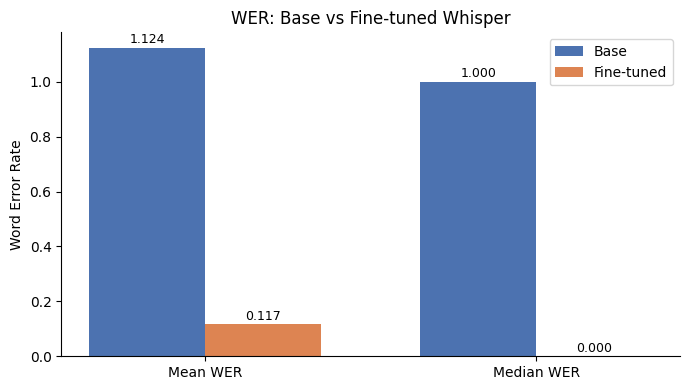

In [38]:
import matplotlib.pyplot as plt
import numpy as np

COLORS = {"base": "#4C72B0", "fine": "#DD8452"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(7, 4))
x, width = np.arange(2), 0.35
bars1 = ax.bar(x - width/2, metrics_df[metrics_df["Metric"].str.contains("WER")]["Base Whisper"],
               width, label="Base", color=COLORS["base"])
bars2 = ax.bar(x + width/2, metrics_df[metrics_df["Metric"].str.contains("WER")]["Fine-tuned Whisper"],
               width, label="Fine-tuned", color=COLORS["fine"])
ax.set_xticks(x); ax.set_xticklabels(["Mean WER", "Median WER"])
ax.set_ylabel("Word Error Rate"); ax.set_title("WER: Base vs Fine-tuned Whisper")
ax.legend()
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

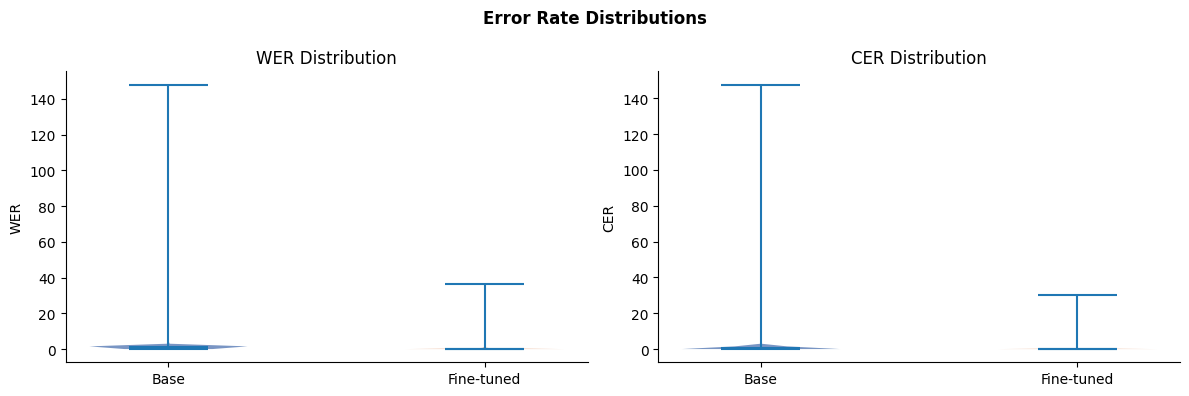

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Violin - WER
parts = axes[0].violinplot(
    [results_df["base_wer"].dropna(), results_df["fine_wer"].dropna()],
    positions=[1, 2], showmedians=True
)
for i, pc in enumerate(parts["bodies"]):
    pc.set_facecolor([COLORS["base"], COLORS["fine"]][i]); pc.set_alpha(0.75)
axes[0].set_xticks([1, 2]); axes[0].set_xticklabels(["Base", "Fine-tuned"])
axes[0].set_ylabel("WER"); axes[0].set_title("WER Distribution")

# Violin - CER
parts2 = axes[1].violinplot(
    [results_df["base_cer"].dropna(), results_df["fine_cer"].dropna()],
    positions=[1, 2], showmedians=True
)
for i, pc in enumerate(parts2["bodies"]):
    pc.set_facecolor([COLORS["base"], COLORS["fine"]][i]); pc.set_alpha(0.75)
axes[1].set_xticks([1, 2]); axes[1].set_xticklabels(["Base", "Fine-tuned"])
axes[1].set_ylabel("CER"); axes[1].set_title("CER Distribution")

plt.suptitle("Error Rate Distributions", fontweight="bold")
plt.tight_layout(); plt.show()

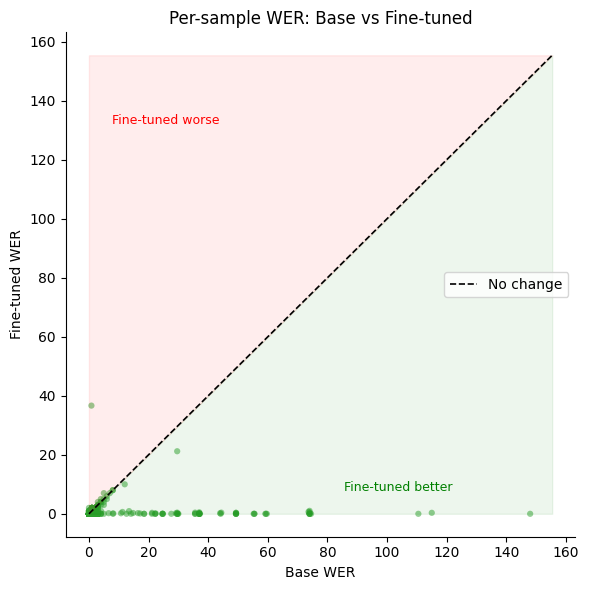

In [40]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(results_df["base_wer"], results_df["fine_wer"],
           alpha=0.5, s=20, color="#2ca02c", edgecolors="none")
lim = max(results_df[["base_wer","fine_wer"]].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1.2, label="No change")
ax.fill_between([0, lim], [0, lim], [0, 0], alpha=0.07, color="green")   # fine-tuned better
ax.fill_between([0, lim], [lim, lim], [0, lim], alpha=0.07, color="red") # fine-tuned worse
ax.text(lim*0.05, lim*0.85, "Fine-tuned worse", color="red",   fontsize=9)
ax.text(lim*0.55, lim*0.05, "Fine-tuned better", color="green", fontsize=9)
ax.set_xlabel("Base WER"); ax.set_ylabel("Fine-tuned WER")
ax.set_title("Per-sample WER: Base vs Fine-tuned"); ax.legend()
plt.tight_layout(); plt.show()

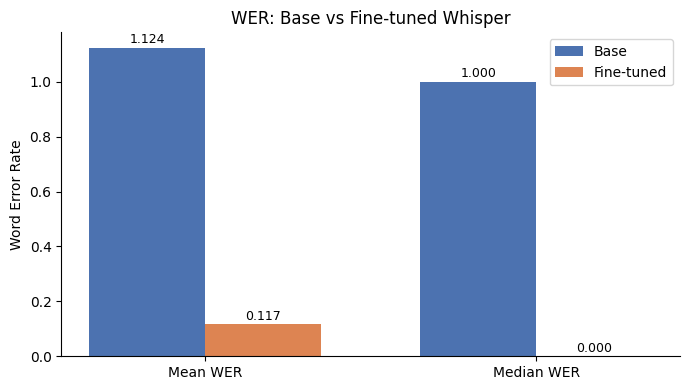

✓ plot1_wer_bar.png


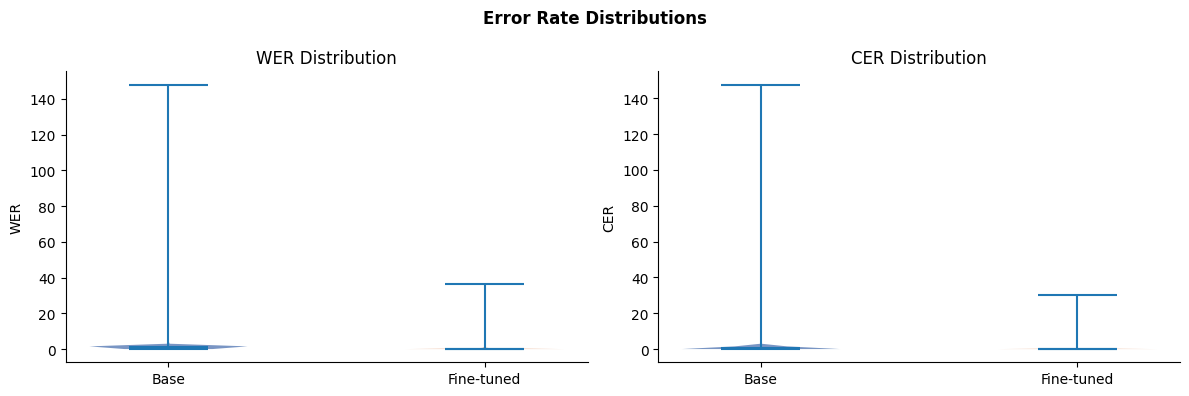

✓ plot2_violin.png


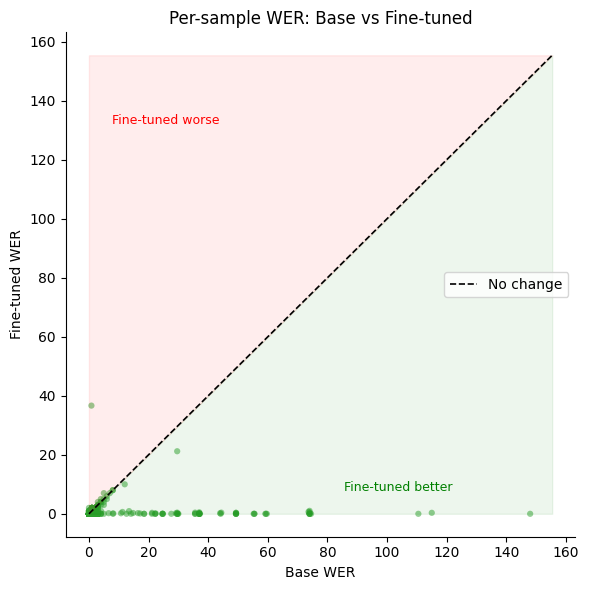

✓ plot3_scatter.png


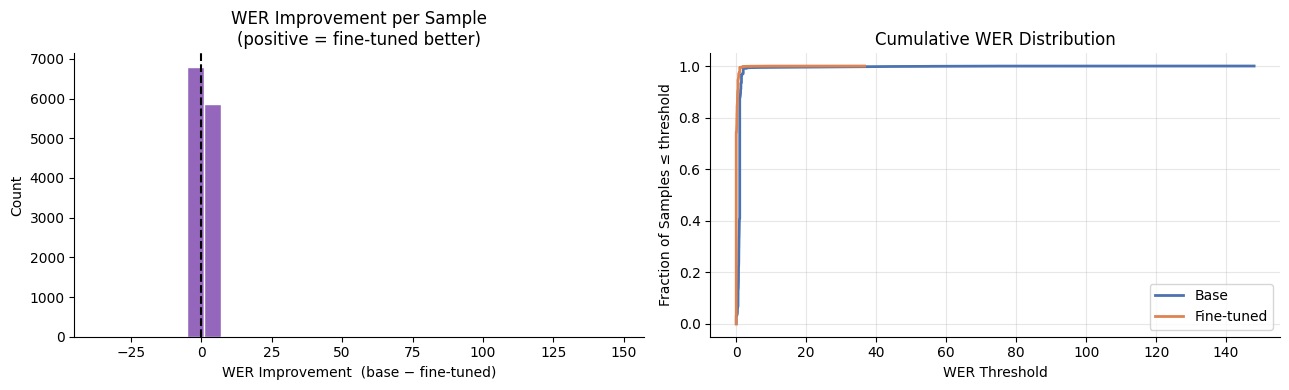

✓ plot4_histogram_cdf.png


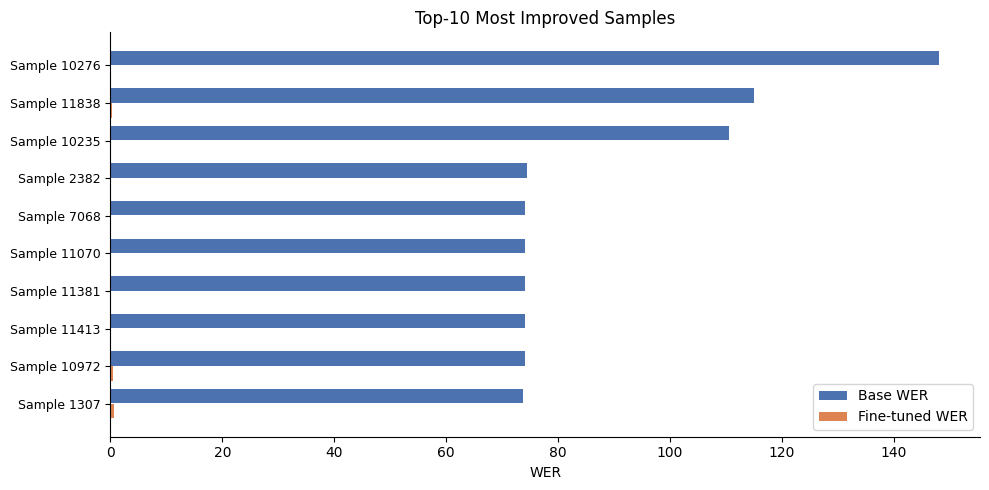

✓ plot5_top10.png

✅ All plots saved! Download 'all_plots.zip' from the Output tab.


In [41]:
import os
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

save_dir = "/kaggle/working/plots"
os.makedirs(save_dir, exist_ok=True)

# ── Plot 1: WER Bar Chart ────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
x, width = np.arange(2), 0.35
wer_rows = metrics_df[metrics_df["Metric"].str.contains("WER")]
bars1 = ax.bar(x - width/2, wer_rows["Base Whisper"],       width, label="Base",       color=COLORS["base"])
bars2 = ax.bar(x + width/2, wer_rows["Fine-tuned Whisper"], width, label="Fine-tuned", color=COLORS["fine"])
ax.set_xticks(x); ax.set_xticklabels(["Mean WER", "Median WER"])
ax.set_ylabel("Word Error Rate"); ax.set_title("WER: Base vs Fine-tuned Whisper")
ax.legend()
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(f"{save_dir}/plot1_wer_bar.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot1_wer_bar.png")

# ── Plot 2: Violin WER & CER ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col_base, col_fine, ylabel, title in [
    (axes[0], "base_wer", "fine_wer", "WER", "WER Distribution"),
    (axes[1], "base_cer", "fine_cer", "CER", "CER Distribution"),
]:
    parts = ax.violinplot([results_df[col_base].dropna(), results_df[col_fine].dropna()],
                          positions=[1, 2], showmedians=True)
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor([COLORS["base"], COLORS["fine"]][i]); pc.set_alpha(0.75)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Base", "Fine-tuned"])
    ax.set_ylabel(ylabel); ax.set_title(title)
plt.suptitle("Error Rate Distributions", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{save_dir}/plot2_violin.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot2_violin.png")

# ── Plot 3: Per-sample Scatter ───────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(results_df["base_wer"], results_df["fine_wer"],
           alpha=0.5, s=20, color="#2ca02c", edgecolors="none")
lim = max(results_df[["base_wer","fine_wer"]].max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1.2, label="No change")
ax.fill_between([0, lim], [0, lim], [0, 0],    alpha=0.07, color="green")
ax.fill_between([0, lim], [lim, lim], [0, lim], alpha=0.07, color="red")
ax.text(lim*0.05, lim*0.85, "Fine-tuned worse",  color="red",   fontsize=9)
ax.text(lim*0.55, lim*0.05, "Fine-tuned better", color="green", fontsize=9)
ax.set_xlabel("Base WER"); ax.set_ylabel("Fine-tuned WER")
ax.set_title("Per-sample WER: Base vs Fine-tuned"); ax.legend()
plt.tight_layout()
plt.savefig(f"{save_dir}/plot3_scatter.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot3_scatter.png")

# ── Plot 4: Improvement Histogram + CDF ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(results_df["wer_improvement"], bins=30, color="#9467bd", edgecolor="white")
axes[0].axvline(0, color="black", lw=1.5, linestyle="--")
axes[0].set_xlabel("WER Improvement  (base − fine-tuned)")
axes[0].set_ylabel("Count")
axes[0].set_title("WER Improvement per Sample\n(positive = fine-tuned better)")
for label, col, c in [("Base", "base_wer", COLORS["base"]), ("Fine-tuned", "fine_wer", COLORS["fine"])]:
    s = np.sort(results_df[col].dropna())
    axes[1].plot(s, np.arange(1, len(s)+1)/len(s), label=label, color=c, lw=2)
axes[1].set_xlabel("WER Threshold"); axes[1].set_ylabel("Fraction of Samples ≤ threshold")
axes[1].set_title("Cumulative WER Distribution")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{save_dir}/plot4_histogram_cdf.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot4_histogram_cdf.png")

# ── Plot 5: Top-10 Most Improved ─────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
top10 = results_df.nlargest(10, "wer_improvement").reset_index()
y = np.arange(len(top10))
ax.barh(y - 0.2, top10["base_wer"], 0.38, color=COLORS["base"], label="Base WER")
ax.barh(y + 0.2, top10["fine_wer"], 0.38, color=COLORS["fine"], label="Fine-tuned WER")
ax.set_yticks(y)
ax.set_yticklabels([f"Sample {i}" for i in top10["index"]], fontsize=9)
ax.set_xlabel("WER"); ax.set_title("Top-10 Most Improved Samples")
ax.legend(); ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{save_dir}/plot5_top10.png", dpi=150, bbox_inches="tight")
plt.show(); print("✓ plot5_top10.png")

# ── Zip everything ───────────────────────────────────────────
import shutil
shutil.make_archive("/kaggle/working/all_plots", "zip", save_dir)
print("\n✅ All plots saved! Download 'all_plots.zip' from the Output tab.")

### Infernce ith the 1500 fine tunned model on all parameters

#### This is for .wav file

In [ ]:
audio_path = "/kaggle/input/my-test-audios/test.wav"

base_pred = transcribe(base_model, audio_path)
fine_pred = transcribe(fine_model, audio_path)

print("Base:", base_pred)
print("Fine:", fine_pred)

#### this is for .wav .mp3 .m4a .ogg types of files

In [9]:
import io
import librosa

def transcribe(model, audio_source):

    # Case 1: uploaded file path
    if isinstance(audio_source, str):
        audio, sr = librosa.load(audio_source, sr=16000)

    # Case 2: bytes from parquet
    else:
        audio_file = io.BytesIO(audio_source)
        audio, sr = librosa.load(audio_file, sr=16000)

    inputs = processor(
        audio,
        sampling_rate=16000,
        return_tensors="pt"
    )

    input_features = inputs.input_features.to(model.device)

    predicted_ids = model.generate(
        input_features=input_features,
        task="transcribe",
        language="ar"
    )

    text = processor.batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    return text

In [27]:
import os
import pandas as pd

audio_folder = "/kaggle/input/datasets/redamalki/darija-audios-fpr-inference/Darija_audio_files_for_inference"

results = []

for file_name in os.listdir(audio_folder):

    audio_path = os.path.join(audio_folder, file_name)

    # support ogg too
    if not file_name.lower().endswith((".wav", ".mp3", ".m4a", ".ogg")):
        continue

    print(f"🎧 Processing: {file_name}")

    base_pred = transcribe(base_model, audio_path)
    fine_pred = transcribe(fine_model, audio_path)

    results.append({
        "audio_file": file_name,
        "base_whisper": base_pred,
        "fine_tuned_whisper": fine_pred
    })

results_df = pd.DataFrame(results)
results_df

🎧 Processing: taha_1.ogg
🎧 Processing: naima.ogg
🎧 Processing: boutarfa.ogg
🎧 Processing: Mouad.ogg
🎧 Processing: taha_2.ogg
🎧 Processing: aymane.ogg
🎧 Processing: naima_2.ogg
🎧 Processing: taha_3.ogg
🎧 Processing: saad.ogg


,audio_file,base_whisper,fine_tuned_whisper
0,taha_1.ogg,صحبا ريضة عني ليه الأمر يادي أبركي تنقل لك لا...,صح بريض عاني ليا الأمورية هادي ابغا تنقول لك ل...
1,naima.ogg,مجموعة ممتاز,مشات للحمام ولا عاد غاتجي منو ولا عاد غاتمشي ل...
2,boutarfa.ogg,رايد أمويا مع شيء لاني شويه ونجيسة عفا ينصفتل...,ريضة موية مع شي علانة شوية ونجي صافي ونصفت لك ...
3,Mouad.ogg,السرداء بلا بشن براك يا أخوية عدينا وعليك بشك...,السريدة على واش نبروك اخويا عاديناو عليك باش ك...
4,taha_2.ogg,ها دي كل دا كن نا قمشينا لا و أخذي زمنة تصاوغ...,هادي قلي داك ناغمشينا الا اخدي تيسين منها التص...
5,aymane.ogg,باريضك سيدي ألف درم واحدة خلال نقطة طول ده بس...,بريضاك سايدي الف درم وحدة خرى دانك الططل دابا ...
6,naima_2.ogg,أعطينا أن نصل إلى الدرجة لتصميم أعطينا أن نكو...,الضروج عيط ليا بشي هزوم معاكم الدراريهبط عندك ...
7,taha_3.ogg,أنا أخوية رخس من جامع ديان أختمت أنا اللي أخب...,انا خويا الله خصت من جامع ديالي ختمتة رانا الل...
8,saad.ogg,ويضعوا على التلفون ديال حسبنا الدانسي بقامل ل...,الطيفون ديالك حساب ناعد داع نسي ب... حساب ناعد...


In [35]:
results_df["fine_tuned_whisper"][0]

'صح بريض عاني ليا الأمورية هادي ابغا تنقول لك لعرفتي شي واحد نتصورو فيه داك تصاور دلاكا'

In [34]:
results_df["fine_tuned_whisper"][1]

'مشات للحمام ولا عاد غاتجي منو ولا عاد غاتمشي ليه دار معايا نيشان متقاش تقتر عليا'

In [33]:
results_df["fine_tuned_whisper"][2]

'ريضة موية مع شي علانة شوية ونجي صافي ونصفت لك وناطك اللعيب'

In [32]:
results_df["fine_tuned_whisper"][3]

'السريدة على واش نبروك اخويا عاديناو عليك باش كتسمينا تنتمى اشاعل الله فالصحيحة والسلامة والشفال الوالد نشع الله طولا لعمر ليه للوالدة وشوف وكون كيما غاون شاع الله  الله حداك السريدة موبلاكتو نتا سندم عليهم غييد عليهم كلوة بقالكم معادع دمباراك ساعيد  لا حداك البرضة'

In [31]:
results_df["fine_tuned_whisper"][4]

'هادي قلي داك ناغمشينا الا اخدي تيسين منها التصاوق تعقل عليها لقيتها كتصلحي اقول لينا قولينا شي بلاصة الله يحميها الوليدين لعندك ضماغ'

In [30]:
results_df["fine_tuned_whisper"][5]

'بريضاك سايدي الف درم وحدة خرى دانك الططل دابا السلام درم ديال لي شد السلام'

In [28]:
results_df["fine_tuned_whisper"][6]

'الضروج عيط ليا بشي هزوم معاكم الدراريهبط عندك رادا ودعا هدا مدعوة وجيد زيدني واحد جوج ديال الفلون كغامل الله يسهل عليك جصا شي ياد الفلون كغامل من عند ملحانوت'

In [29]:
print(results_df["fine_tuned_whisper"][7])

انا خويا الله خصت من جامع ديالي ختمتة رانا اللابع فما كنتفخ باغي الصراحة الله
